# Deneme — VGG16 Öznitelikleri + SVM ile Sınıflandırma

Bu notebook, derin öğrenme tabanlı sınıflandırıcılardan önce denenen **klasik
makine öğrenmesi** yaklaşımını gösterir: ImageNet üzerinde eğitilmiş VGG16, öznitelik
çıkarıcı olarak kullanılır ve çıkan öznitelik vektörleri üzerine bir SVM
(destek vektör makinesi) eğitilir.

## Neden halka açık bir veri kümesi?

Amaç, yöntemin **kod hattını** (pipeline) doğrulamaktır: VGG16 çıkarımı → öznitelik
düzleştirme → SVM eğitimi → karışıklık matrisi. Bunun için halka açık
`cats-and-dogs-image-classification` veri kümesi kullanılmıştır; sonuçlar akciğer
verisiyle ilgili **değildir** ve bu notebook yalnızca yöntem denemesi olarak
tutulmaktadır.

## Neden üretimde kullanılmadı?

* **Öznitelik düzleştirme (Flatten) kaybı:** VGG16'nın `7×7×512` çıktısı düz bir
  vektöre çevrildiğinde konum bilgisi tamamen kaybolur. Akciğer kesitlerinde
  lezyon küçük bir bölgede olduğu için bu, en kritik bilginin atılması anlamına gelir.
* **Ölçeklenme:** Eğitim kümesinin tamamı için VGG16 çıkarımı yapılması gerekir;
  yeni veri geldiğinde tüm SVM yeniden eğitilmelidir (uçtan uca ince ayar yapılamaz).
* **Sonuç:** Aynı görevde InceptionV3 tabanlı uçtan uca model (`notebooks/03`)
  belirgin şekilde daha iyi sonuç verdiği için SVM yaklaşımı terk edilmiştir.


In [ ]:
# Colab kullanıyorsanız:
# from google.colab import drive
# drive.mount("/content/drive")
# %pip install -q kaggle tensorflow scikit-learn

import os
import glob

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing, svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tensorflow.keras.applications.vgg16 import VGG16

# ---------------------------------------------------------------- yollar
DATA_ROOT = "/content/cats-and-dogs-image-classification"
INPUT_SIZE = (224, 224)
SEED = 42


## 1. Veri kümesinin indirilmesi

Kaggle API anahtarı (`kaggle.json`) Colab'ın kendi dosya yükleme arayüzü ile
verilir. Anahtarı notebook'a yazmayın; arayüz üzerinden yükleyin.

```python
from google.colab import files
files.upload()          # kaggle.json
```

Ardından:

```bash
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d samuelcortinhas/cats-and-dogs-image-classification
!unzip -q cats-and-dogs-image-classification.zip
```

> **Önceki sürümdeki sorun:** Kaggle komutları `!` öneki olmadan hücreye
> yazılmıştı (`mkdir ~/.kaggle`, `cp kaggle.json ...`). Python yorumlayıcısı bu
> satırları çalıştıramaz; komutlar ancak hücrenin başına `!` eklenirse çalışır.


## 2. Görüntülerin yüklenmesi

Tüm görüntüler 224×224'e indirgenir ve VGG16'nın beklediği RGB düzenine çevrilir.

> **Önceki sürümdeki hata:** `cv2.imread` zaten **BGR** döndürür; ardından
> `cv2.cvtColor(img, cv2.COLOR_RGB2BGR)` uygulanıyordu. Bu, kanalları ikinci kez
> çevirir ve görüntüyü **ters renklerle** modele verir. Doğrusu `COLOR_BGR2RGB`.


In [ ]:
def load_images(root_dir, extensions=(".jpg", ".png")):
    """Bir klasördeki sınıf alt klasörlerinden görüntüleri yükler.

    Returns:
        (görüntüler, etiketler) — etiketler klasör adlarıdır.
    """
    images, labels = [], []

    for class_dir in sorted(glob.glob(os.path.join(root_dir, "*"))):
        if not os.path.isdir(class_dir):
            continue
        class_name = os.path.basename(class_dir)

        for path in sorted(glob.glob(os.path.join(class_dir, "*"))):
            if not path.lower().endswith(extensions):
                continue

            image = cv2.imread(path, cv2.IMREAD_COLOR)
            if image is None:
                continue

            image = cv2.resize(image, INPUT_SIZE)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)   # VGG16 RGB bekler
            images.append(image)
            labels.append(class_name)

        print(f"{class_name:>10}: son sayım {len(images)} görüntü")

    return np.array(images), np.array(labels)


train_images, train_labels = load_images(os.path.join(DATA_ROOT, "train"))
test_images, test_labels = load_images(os.path.join(DATA_ROOT, "test"))

print()
print("Eğitim:", train_images.shape, "| Test:", test_images.shape)


## 3. Etiket kodlaması

> **Önceki sürümdeki sorun:** `LabelEncoder` iki kez `fit` ediliyordu — önce test,
> sonra eğitim etiketleri üzerinde. Aynı etiket kümesi için sonuç aynı olsa da bu
> yaklaşım kırılgandır: kümeler farklı sınıflar içerirse kodlama tutarsız olur.
> Bu sürümde kodlayıcı **tüm** etiketler üzerinde bir kez eğitilir.


In [ ]:
encoder = preprocessing.LabelEncoder()
encoder.fit(np.concatenate([train_labels, test_labels]))

y_train = encoder.transform(train_labels)
y_test = encoder.transform(test_labels)

print("Sınıflar:", list(encoder.classes_))
print("Eğitim dağılımı:", dict(zip(*np.unique(train_labels, return_counts=True))))
print("Test dağılımı  :", dict(zip(*np.unique(test_labels, return_counts=True))))


## 4. VGG16 ile öznitelik çıkarımı

Model yalnızca **öznitelik çıkarıcıdır**: `include_top=False` ile sınıflandırma
katmanları çıkarılır ve tüm katmanlar dondurulur. Çıktı `7×7×512` boyutundadır ve
düz bir vektöre (25088) dönüştürülür.


In [ ]:
vgg_model = VGG16(weights="imagenet", include_top=False, input_shape=(*INPUT_SIZE, 3))
vgg_model.trainable = False

print("VGG16 parametre sayısı:", vgg_model.count_params())

train_features = vgg_model.predict(train_images, batch_size=32, verbose=1)
print("Çıkarılan öznitelik haritası:", train_features.shape)

# Düzleştirme: (N, 7, 7, 512) -> (N, 25088)
train_vectors = train_features.reshape(train_features.shape[0], -1)
print("Öznitelik vektörü boyutu:", train_vectors.shape)

test_features = vgg_model.predict(test_images, batch_size=32, verbose=1)
test_vectors = test_features.reshape(test_features.shape[0], -1)


## 5. SVM eğitimi

Doğrusal çekirdek (`linear`) kullanılır. Öznitelik boyutu (25088) örnek sayısından
çok daha büyük olduğu için doğrusal çekirdek en uygun seçimdir; RBF çekirdeği bu
boyutta hem yavaş hem de aşırı öğrenmeye açıktır.


In [ ]:
classifier = svm.SVC(kernel="linear", C=2, gamma="auto")
classifier.fit(train_vectors, y_train)

predictions = classifier.predict(test_vectors)
accuracy = accuracy_score(y_test, predictions)

print(f"Test doğruluğu: {accuracy:.4f}")
print()
print(classification_report(y_test, predictions, target_names=list(encoder.classes_)))


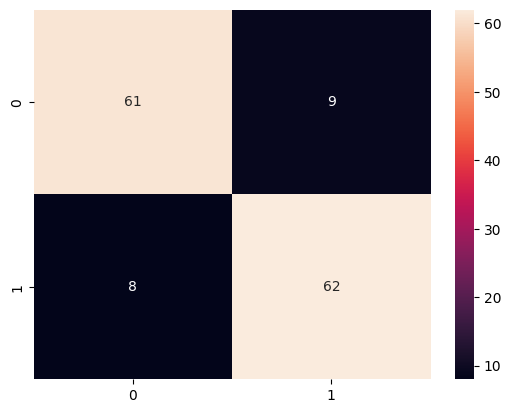

In [ ]:
conf_matrix = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=list(encoder.classes_),
            yticklabels=list(encoder.classes_))
plt.xlabel("Tahmin edilen")
plt.ylabel("Gerçek")
plt.title("SVM — Karışıklık Matrisi (cats vs dogs)")
plt.show()


## Sonuç

* Yöntem hattı **çalışır**: yalnızca 985 eğitim görüntüsüyle %77 civarında bir test
  doğruluğu elde edilmiştir. Bu, eğitilebilir parametresi olmayan ("eğitimsiz")
  bir öznitelik çıkarıcı ile iki sınıflı bir problemde makul bir sonuçtur.
* Ancak yöntem **akciğer verisi için uygun değildir**:
  * `Flatten` konum bilgisini yok eder; lezyon tespitinde bu bilgi kritiktir.
  * SVM olasılık çıktısı vermez (`probability=False`), yani model belirsizliği
    raporlanamaz.
  * Yeni veri geldiğinde tüm öznitelikler ve SVM yeniden hesaplanmalıdır.
* Bu nedenlerle çalışmanın geri kalanında uçtan uca derin öğrenme
  (`notebooks/03` sınıflandırma, `notebooks/07` segmentasyon) kullanılmıştır.

### Notlar

* Bu notebook **halka açık** bir veri kümesi kullanır; hasta verisi içermez.
* Sonuçlar akciğer görüntüleriyle ilgili hiçbir iddia içermez.
